# Statystyka matematyczna - ćwiczenia laboratoryjne 2023/2024

Ten notatnik zalicza się do grupy zestawów zadań, na podstawie których odbywa się zaliczenie ćwiczeń i podlega zwrotowi do oceny w ustalonym na zajęciach terminie.

Uwagi i wytyczne ogólne dotyczące uzupełniania notatnika:
- Podczas wykonywania zadań należy korzystać wyłącznie z pakietów zaimportowanych na początku notatnika oraz z pakietów wchodzących w skład standardowej biblioteki Pythona, które można zaimportować samodzielnie we wskazanej komórce notatnika.
- Swoje rozwiązania należy wprowadzać wyłącznie w miejce następujących fragmentów kodu:<br/> `# YOUR CODE HERE`<br/> `raise NotImplementedError()`<br/> 
a odpowiedzi tekstowe w komórkach oznaczonych hasłem:<br/> 
`YOUR ANSWER HERE`<br/> 
Nie należy w żaden sposób modyfikować pozostałych fragmentów kodu oraz innych elementów notatnika, w szczególności dodawać lub usuwać komórek oraz zmieniać nazwy pliku.
- Otrzymywane wyniki i odpowiedzi mają być rezultatem wykonania napisanego kodu.
- Zadanie należy wykonać w taki sposób, aby podczas wykonywania kodu nie zostały wyświetlone żadne ostrzeżenia.
- Zawarte w notatniku automatyczne testy mają charakter poglądowy. Dotyczą one wybranych aspektów zadań i mają za zadanie wyłapać podstawowe błędy. Przejście wszystkich testów nie oznacza, że zadanie jest wykonane w całości poprawnie.

Uwagi i wytyczne ogólne dotyczące wizualizacji wyników:
- Wszystkie wykresy powinny być wykonane w jednolitym, przejrzystym i czytelnym stylu, posiadać odpowiednio dobrane proporcje i zakresy wartości osi.
- Wykresy oraz ich osie powinny mieć nadane tytuły. Jeżeli w obrębie figury znajduje się więcej niż jeden wykres to figura również powinna mieć nadany tytuł. 
- Figury powinny mieć ustawione białe tło, tak, aby niezależnie od ustawień notatnika wszystkie elementy wykresów były dobrze widoczne (domyślnie tło jest przeźroczyste co może powodować problemy w notatnikach z ustawionym ciemnym tłem).
- Rozmiar poziomy figur nie powinien przekraczać 20 cali.

Przed odesłaniem zestawu zadań do oceny proszę uzupełnić komórkę z danymi autorów rozwiązania (nazwa zespołu oraz imiona, nazwiska i numery indeksów członków zespołu) oraz upewnić się, że notatnik działa zgodnie z oczekiwaniami. W tym celu należy skorzystać z opcji **Restart Kernel and Run All Cells...** dostępnej na górnej belce notatnika pod symbolem $\blacktriangleright\blacktriangleright$.

Nazwa zespołu:
Członkowie:

---

# Zestaw zadań 7: Estymacja nieparametryczna

In [1]:
import numpy as np
import pandas as pd
import scipy as sp
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KernelDensity

In [2]:
# Miejsce do importu pakietów wchodzących w skład standardowej biblioteki Pythona oraz ustawienie opcji wykorzystywanych pakietów

### Dane do zadań

W celu wygenerowania danych wykonaj poniższą komórkę.

In [3]:
# Dane do testów 1
sample = pd.DataFrame(data=np.concatenate([sp.stats.norm.rvs(loc=4, scale=0.2, size=45, random_state=7), sp.stats.norm.rvs(loc=5.5, scale=0.4, size=85, random_state=2159)]), columns=["X"])
sample.head()

,X
0,4.338105
1,3.906813
2,4.006564
3,4.081503
4,3.842215


### Zadanie 1: Histogram [5 pkt]

#### a) Przygotowanie wykresów

Korzystając z funkcji `seaborn.histplot()`przygotuj histogramy częstości zestawu danych zawartego w zmiennej `sample`.

Wykresy zestaw na pojedynczej figurze (2x3 pola na wykres). Przygotowując figurę kieruj się wytycznymi z początku notatnika. Podczas wykonywania kolejnych histogramów:
 - nie ustawiaj żadnych wartość określających podział na przedziały oraz granice przedziałów,
 - ustaw wyłącznie liczbę przedziałów na 20,
 - ustaw wyłącznie szerokość przedziałów na 0.3,
 - ustaw granice przedziałów od 2 do 8 z krokiem 0.05,
 - ustaw granice przedziałów od 2 do 8 z krokiem 0.15,
 - ustaw granice przedziałów od 2 do 8 z krokiem 0.4.
 
Do każdego z wykresów dodaj wizualną reprezentację zestawu danych w postaci zbioru symboli (| lub +) zlokalizowanych poniżej histogramu. Ustaw identyczne zakresy osi dla wszystkich wykresów.

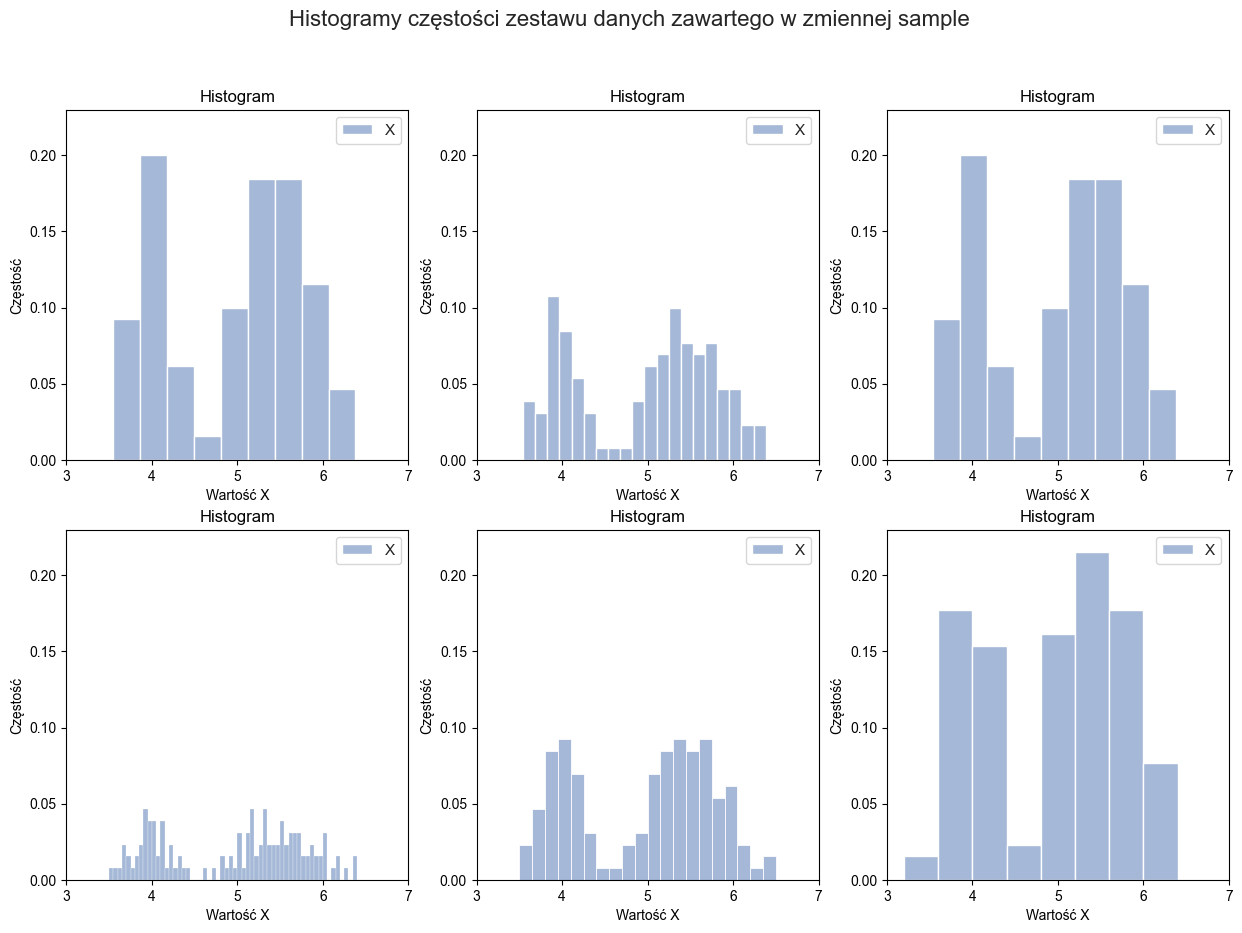

In [4]:
# YOUR CODE HERE
# Utworzenie figury i osi subplotów
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Ustawienie stylu seaborn
sns.set(style="whitegrid")

sns.histplot(sample, stat='probability',  ax=axes[0,0])
sns.histplot(sample, stat='probability',bins=20, ax=axes[0,1])
sns.histplot(sample, stat='probability', binwidth=0.3, ax=axes[0,2])
bin1 = np.arange(2, 8, 0.05)
bin2 = np.arange(2, 8, 0.15)
bin3 = np.arange(2, 8, 0.4)
sns.histplot(sample, bins=bin1, stat='probability', ax=axes[1,0])
sns.histplot(sample, bins=bin2, stat='probability', ax=axes[1,1])
sns.histplot(sample, bins=bin3, stat='probability', ax=axes[1,2])

sns.scatterplot( data=sample, x="X", y=-0.01, marker='|', color='black', alpha=0.3, ax=axes[0,0])
sns.scatterplot( data=sample, x="X", y=-0.01, marker='|', color='black', alpha=0.3, ax=axes[0,1])
sns.scatterplot( data=sample, x="X", y=-0.01, marker='|', color='black', alpha=0.3, ax=axes[0,2])
sns.scatterplot( data=sample, x="X", y=-0.01, marker='|', color='black', alpha=0.3, ax=axes[1,0])
sns.scatterplot( data=sample, x="X", y=-0.01, marker='|', color='black', alpha=0.3, ax=axes[1,1])
sns.scatterplot( data=sample, x="X", y=-0.01, marker='|', color='black', alpha=0.3, ax=axes[1,2])


fig.suptitle('Histogramy częstości zestawu danych zawartego w zmiennej sample', fontsize=16)

# Ustawienie identycznych zakresów osi i dodatnie tytułów dla wszystkich wykresów
for ax_row in axes:
    for ax in ax_row:
        ax.set_xlim(3, 7)
        ax.set_ylim(0, 0.23)
        ax.set_xlabel("Wartość X")
        ax.set_ylabel("Częstość")
        ax.set_title("Histogram")

#raise NotImplementedError()

### Zadanie 2: Estymacja funkcją jądrową [16 pkt]

#### a) Estymacji funkcjami jądrowymi od podstaw

Przygotuj funkcję `simple_kde_estimation()`, która będzie dokonywała estymacji nieparametrycznej metodą funkcji jądrowych z wykorzystaniem jądra w postaci rozkładu normalnego o odchyleniu normalnym $\sigma$ zgodnie z informacjami zawartymi w docstring funkcji oraz schematem z załączonego do notatnika zestawu wzorów.

Poza zwracaniem danych określonych w docstring funkcji powinna ona generować wykres zawierający wyestymowaną funkcję (wykres liniowy z wypełnionym polem pod krzywą) oraz dodaną wizualną reprezentacją zestawu danych w postaci zbioru symboli (| lub +) zlokalizowanych poniżej wykresu.

Uwagi do wykonania zadania:
 - Punkty estymacji wygeneruj za pomocą funkcji `numpy.linspace()` lub `numpy.arange()`.
 - Wartości gęstości prawdopodobieństwa oblicz za pomocą odpowiedniej funkcji z modułu `scipy.stats.norm`.
 - Przygotowując figurę kieruj się wytycznymi z początku notatnika.

In [5]:
def simple_kde_estimation(data, estimation_points, sigma):
    """
    Parameters
    -------
    data: DataFrame
        Tablica zawierająca domyślny indeks i pojedynczą kolumnę "X" z wartościami próby losowej.
    estimation_points: int
        Liczba punktów estymacji funkcji gęstości prawdopodobieństwa.
    sigma: float
        Odchylenie standardowe rozkładu normalnego wykorzystywanego jako jądro funkcji.
    
    Returns
    -------
    cdf: DataFrame
        Tablica zawierająca następujące kolumny:
        X - uszeregowane rosnąco punkty estymacji funkcji gęstości prawdopodobieństwa,
        KDE - wyestymowane wartości funkcji gęstości prawdopodobieństwa.
    """
    # YOUR CODE HER
    x_min = data['X'].min()
    x_max = data['X'].max()
    
    # Generowanie punktów estymacji
    points = np.linspace(x_min - 3 * sigma, x_max + 3 * sigma, estimation_points)
    
    # Obliczanie wartości funkcji gęstości dla każdego punktu estymacji
    kde_values = np.zeros(estimation_points)
    for i, x in enumerate(points):
        kde_values[i] = np.sum(sp.stats.norm.pdf((x - data['X']) / sigma)) / len(data)
    
    # Standaryzacja otrzymanych wartości
    kde_values /= np.sum(kde_values) * (points[1] - points[0])
    
    # Tworzenie DataFrame z wynikami
    cdf = pd.DataFrame({'X': points, 'KDE': kde_values})
    
    # Rysowanie wykresu
    plt.plot(cdf['X'], cdf['KDE'], linewidth=2)
    plt.fill_between(cdf['X'], 0, cdf['KDE'], alpha=0.3)
    plt.scatter(data['X'], np.zeros_like(data['X']) - 0.025, marker='|', color='black', alpha=0.3)
    plt.xlabel('Wartość')
    plt.ylabel('Gęstość prawdopodobieństwa')
    plt.title('Estymacja funkcji gęstości metodą jądrową')
    plt.show()
    
    return cdf

    #raise NotImplementedError()

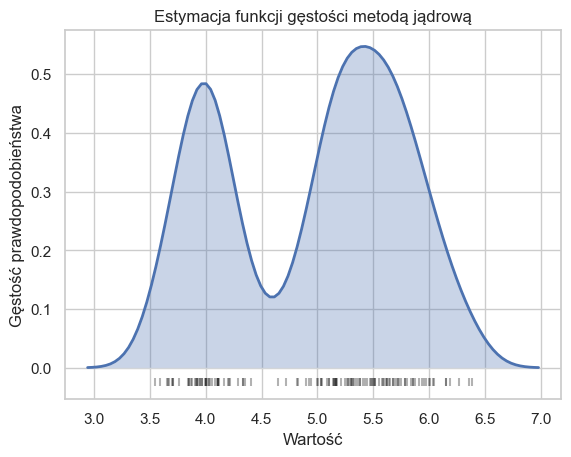

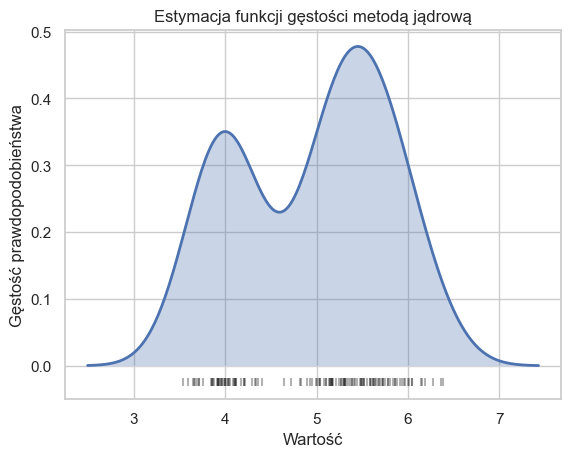

In [6]:
# Komórka testowa
test_results_1 = simple_kde_estimation(sample, estimation_points=100, sigma=0.2)
assert type(test_results_1) == pd.DataFrame
assert test_results_1.shape == (100, 2)
assert list(test_results_1.columns) == ['X', 'KDE']
assert np.all(np.isclose(test_results_1.min().values, [2.94233698e+00, 3.32813073e-04]))
assert np.all(np.isclose(test_results_1.max().values, [6.98176057, 0.54688772]))
assert np.all(np.isclose(test_results_1.mean().values, [4.96204877, 0.24508447]))

test_results_2 = simple_kde_estimation(sample, estimation_points=250, sigma=0.35)
assert type(test_results_2) == pd.DataFrame
assert test_results_2.shape == (250, 2)
assert list(test_results_2.columns) == ['X', 'KDE']
assert np.all(np.isclose(test_results_2.min().values, [2.49233698e+00, 2.69768435e-04]))
assert np.all(np.isclose(test_results_2.max().values, [7.43176057, 0.47782523]))
assert np.all(np.isclose(test_results_2.mean().values, [4.96204877, 0.20164296]))

#### b) Dedykowane funkcje

Korzystając z klasy `KernelDensity` wchodzącej w skład pakietu scikit-learn dokonaj estymymacji rozkładu zestawu danych zawartego w zmiennej `sample`.

Wyniki estymacji przedstaw w postaci wykresów zawierających wyestymowaną funkcję (wykres liniowy z wypełnionym polem pod krzywą) oraz dodaną wizualną reprezentacją zestawu danych w postaci pionowych kresek zlokalizowanych poniżej wykresu.

Wykresy zestaw na dwóch figurach (2x3 pola na wykres). Przygotowując figury kieruj się wytycznymi z początku notatnika. Podczas wykonywania wykresów:
 - Figura 1:
     - na każdym z wykresów przedstaw wynik estymacji z wykorzystaniem innego jądra funkcji,
     - ustaw wartość parametru odpowiadającego za szerokość jądra funkcji na 0.1,
     - ustaw identyczne zakresy osi dla wszystkich wykresów.
 - Figura 2:
     - na każdym z wykresów przedstaw wynik estymacji z wykorzystaniem innego jądra funkcji,
     - ustaw wartość parametru odpowiadającego za szerokość jądra funkcji tak, aby wynik pracy funkcji dobrze oddawał charakter rozkładu populacji z której została pobrana próba losowa,
     - ustaw identyczne zakresy osi dla wszystkich wykresów. 

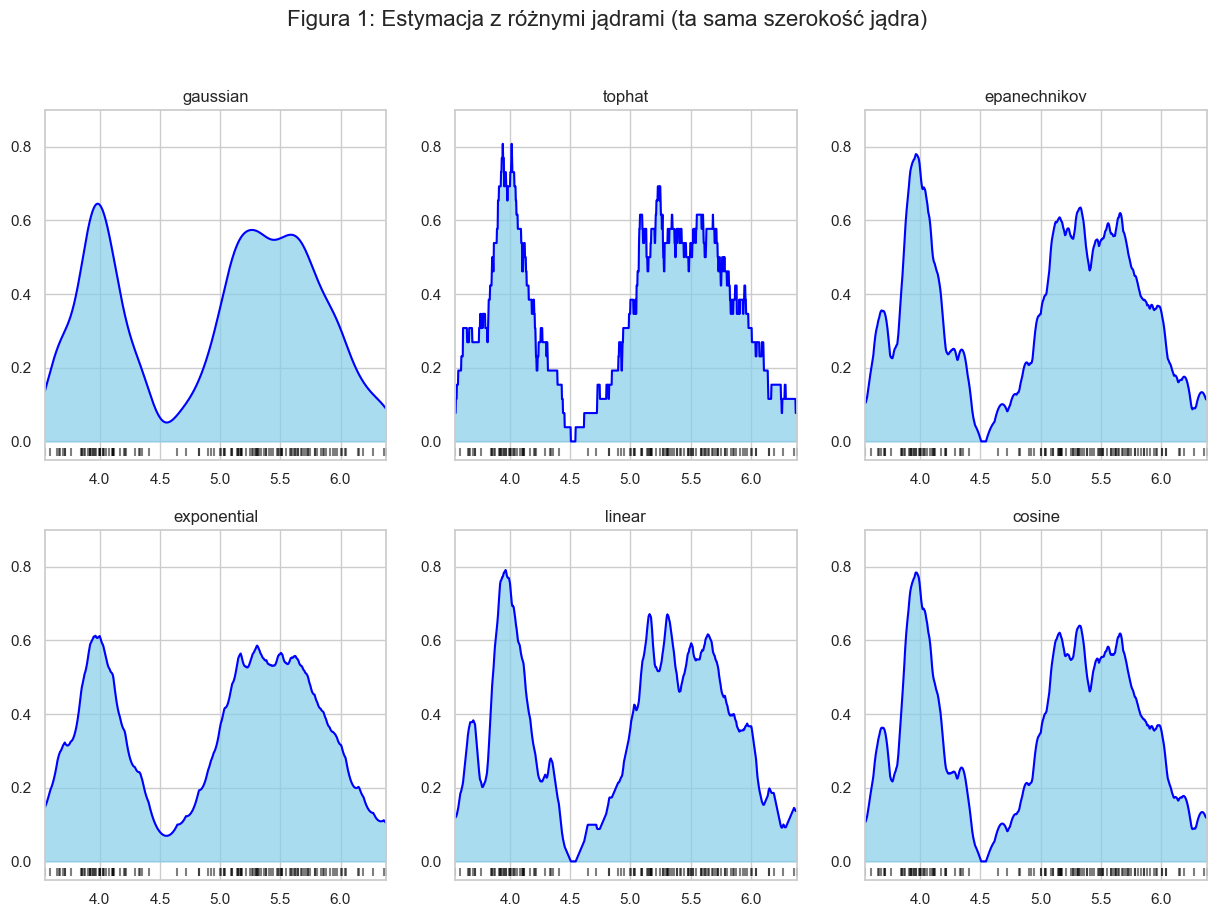

In [7]:
# Figura 1
# YOUR CODE HERE
# Zakres osi X
x_min = sample.min().values[0]
x_max = sample.max().values[0]

# Punkty dla estymacji
x_points = np.linspace(x_min, x_max, 1000)
kernels = ['gaussian', 'tophat', 'epanechnikov', 'exponential', 'linear', 'cosine']
# Tworzenie pierwszej figury
fig1, axes1 = plt.subplots(2, 3, figsize=(15, 10), facecolor="white")

for i, kernel in enumerate(kernels):
    # Tworzenie estymatora
    kde = KernelDensity(bandwidth=0.1, kernel=kernel)
    sample_values = sample['X'].values
    sample_values_reshaped = sample_values.reshape(-1, 1)
    kde.fit(sample_values_reshaped) 
    
    # Generowanie punktów dla estymacji
    log_dens = kde.score_samples(x_points.reshape(-1, 1))
    dens = np.exp(log_dens)

    # Wykres estymacji
    ax = axes1[i // 3, i % 3]
    ax.plot(x_points, dens, color='blue', label='Estymowana funkcja gęstości')
    ax.fill_between(x_points, dens, color='skyblue', alpha=0.7)
    
    ax.scatter(sample["X"], np.full_like(sample["X"], -0.03), marker='|', color='black', alpha=0.5)
    ax.set_title(f'{kernel}')
    ax.set_xlim(x_min, x_max)
    ax.set_ylim([-0.05, 0.9]) 

fig1.suptitle('Figura 1: Estymacja z różnymi jądrami (ta sama szerokość jądra)', fontsize=16)
plt.show()

#raise NotImplementedError()

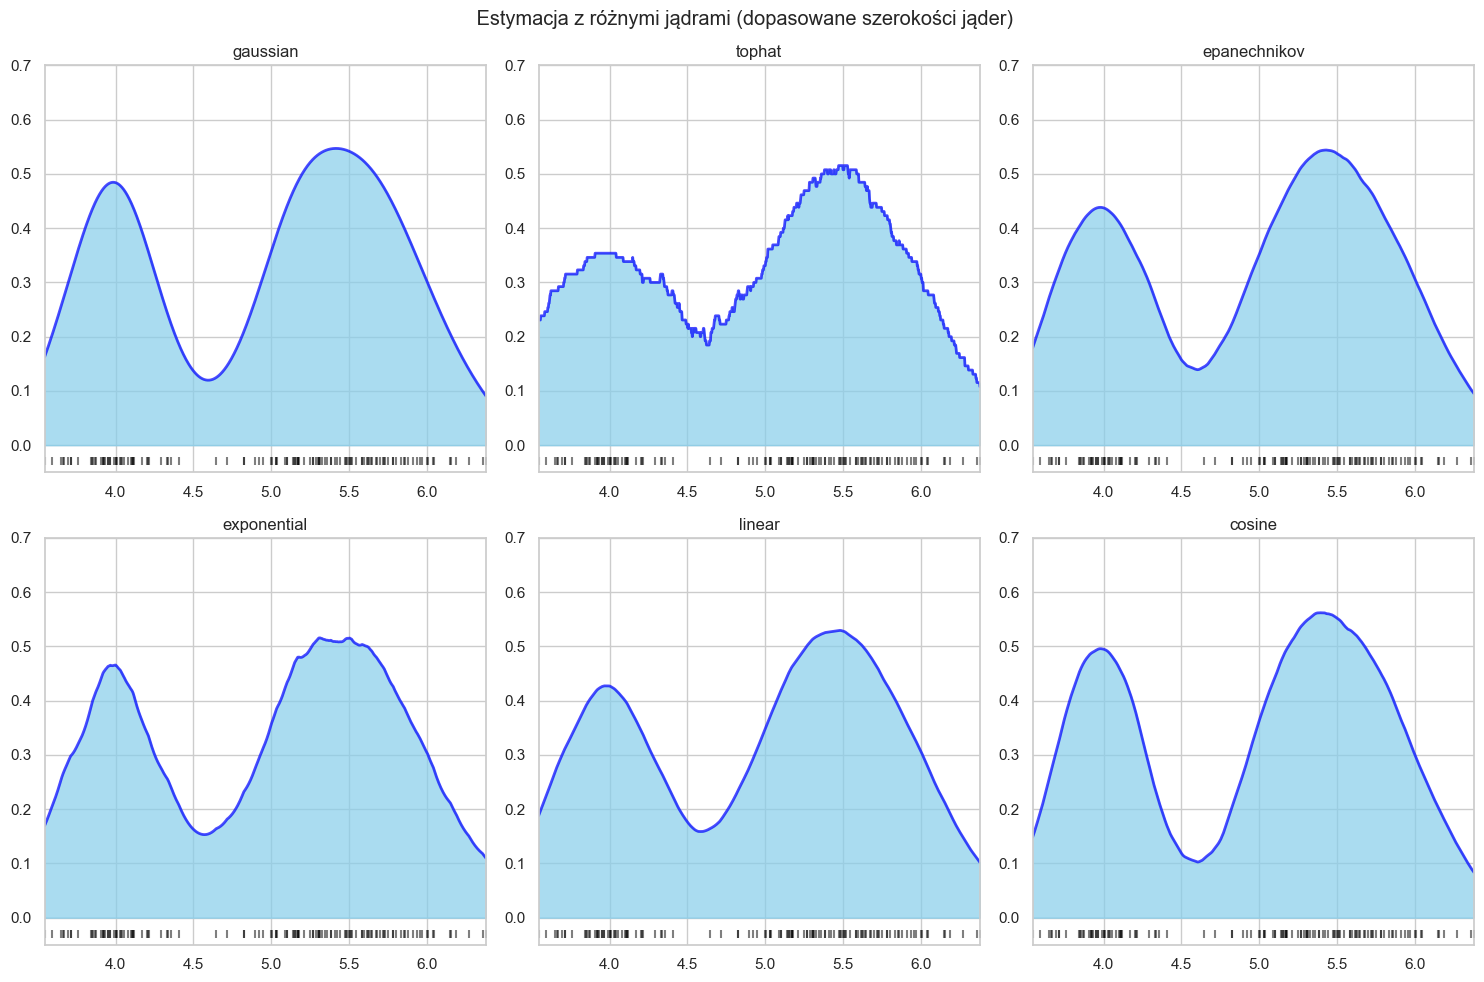

In [8]:
# Figura 2
# YOUR CODE HERE
# Tworzenie figury
fig, axes = plt.subplots(2, 3, figsize=(15, 10), facecolor="white")
fig.suptitle(" Estymacja z różnymi jądrami (dopasowane szerokości jąder)")

# Listy kerneli i szerokości dla każdego kernela
kernels = ['gaussian', 'tophat', 'epanechnikov', 'exponential', 'linear', 'cosine']
bandwidths = [0.2, 0.5, 0.5, 0.2, 0.6, 0.4]

# Iteracja po wszystkich kernelach
for i, (kernel, bandwidth) in enumerate(zip(kernels, bandwidths)):
    # Estymacja dla danego jądra i szerokości jądra
    kde = KernelDensity(kernel=kernel, bandwidth=bandwidth).fit(sample.values)
    x_vals = np.linspace(x_min, x_max, 1000)
    log_dens = kde.score_samples(x_vals.reshape(-1, 1))
    dens = np.exp(log_dens)
    
    # Wykres estymacji
    ax = axes[i // 3, i % 3]
    ax.plot(x_vals, dens, color='blue', alpha=0.7, linewidth=2)
    ax.fill_between(x_vals, dens, color='skyblue', alpha=0.7)
    ax.scatter(sample["X"], np.full_like(sample["X"], -0.03), marker='|', color='black', alpha=0.5)
    ax.set_title(f"{kernel}")
    ax.set_xlim([x_min, x_max])
    ax.set_ylim([-0.05, 0.7]) 
   
plt.tight_layout()
plt.show()

#raise NotImplementedError()

### Zadanie 3: Dyskusja wyników [6 pkt]

Przygotowane w poprzednich zadaniach wykresy są wizualną reprezentacją tego samego zestawu danych, dobór metody oraz jej parametrów sparawia jednak, że nie wyglądają one identycznie.

Przedyskutuj plusy i minusy obu metod oraz odpowiedz na pytanie w jaki sposób dobór parametrów funkcji (liczba, szerokość i położenie granic przedziałów, wykorzystana wersja oraz szerokość jadra) wpływa na poprawność i czytelność wyniku.

YOUR ANSWER HERE
Histogram jest zarówno prosty w tworzeniu jak i w interpretacji, gdyż widać na każdym słupku częstość występowania w określonym przedziale. Jednak ma też minusy bo nie pokazuję ciągłego i gładkiego rozkładu danych pomiędzy przedziałami i w łatwy sposób możemy utracić istotne informację, gdyż dobór odpowiednich przedziałów jest kluczowy 
W odróżnieniu od histogramu estymacja jądrowa uwzględnia gładkie przejścia pomiędzy danymi wartościami i jest dokładniejsza dla nieregularnych danych. Jest też mniej wrażliwa na dobór liczby przedziałów, natomiast przy doborze szerokości jądra trzeba być bardziej ostrożnym bo w łatwy sposób mozna spłaszczyć estymację lub zbyt dopasować do danych. Z pewnością jest tez trudniejsza w tworzeniu jak i interpretacji.

### Zadanie 4: Estymacja na podstawie dystybuanty [8 pkt]

Przygotuj funkcję `cdf_estimation()`, która będzie dokonywała estymacji dystrybuanty rozkładu w oparciu o dystrybuantę empiryczną oraz statystykę wyznaczaną z rozkładu Kołmogorowa-Smirnowa zgodnie z informacjami zawartymi w docstring funkcji oraz schematem z załączonego do notatnika zestawu wzorów.

Poza zwracaniem danych określonych w docstring funkcji powinna ona generować wykres liniowy dystrybuanty empirycznej z zaznaczonym przedziałem ufności oraz tytułem figury `Przedział ufności dystrybuanty rozkładu na poziomie istotności 1-alpha=A`, gdzie wartość A jest uzupełnianie na podstawie wartości argumentu `alpha`.

Uwagi do wykonania zadania:
 - Wartości statystyki testowej oblicz za pomocą odpowiedniej funkcji z modułu `scipy.stats.kstwo`.

In [9]:
def cdf_estimation(data, alpha):
    """
    Parameters
    -------
    data: DataFrame
        Tablica zawierająca domyślny indeks i pojedynczą kolumnę "X" z wartościami próby losowej.
    alpha: float
        Wartość określająca poziom istotności.
    
    Returns
    -------
    cdf: DataFrame
        Tablica zawierająca następujące kolumny:
        X - uszeregowane rosnąco wartości próby losowej,
        F_d - wartości dystrybuanty empirycznej,
        F_d_min - dolna granica przedziału ufności,
        F_d_max - górna granica przedziału ufności.
    """
    # YOUR CODE HERE

    data_sorted = data.sort_values(by='X')
    n = len(data_sorted)

    data_sorted['F_d'] = np.arange(1, n + 1) / n

    # Obliczenie wartości statystyki Kołmogorowa-Smirnowa
    D_alpha_n = sp.stats.kstwo.ppf(1-alpha, n)

    # F_d_min - dolna granica przedziału ufności
    data_sorted['F_d_min'] = np.maximum(0, data_sorted['F_d'] - D_alpha_n)

    # F_d_max - górna granica przedziału ufności
    data_sorted['F_d_max'] = np.minimum(1, data_sorted['F_d'] + D_alpha_n)

    # Wykres
    plt.plot(data_sorted['X'], data_sorted['F_d'], label='Dystrybuanta empiryczna',color='red')
    plt.fill_between(data_sorted['X'], data_sorted['F_d_min'], data_sorted['F_d_max'], alpha=0.2, color='gray')
    plt.title(f'Przedział ufności dystrybuanty rozkładu na poziomie istotności 1-alpha={alpha}')
    plt.xlabel('X')
    plt.ylabel('Dystrybuanta empiryczna')
    plt.legend()
    plt.grid(False)
    plt.show()

    return data_sorted[['X', 'F_d', 'F_d_min', 'F_d_max']]

    #raise NotImplementedError()

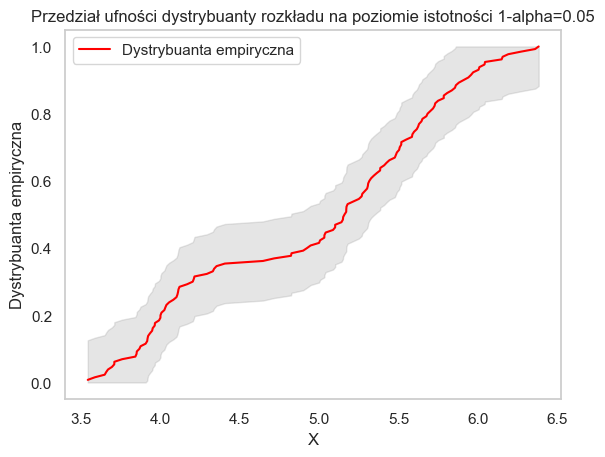

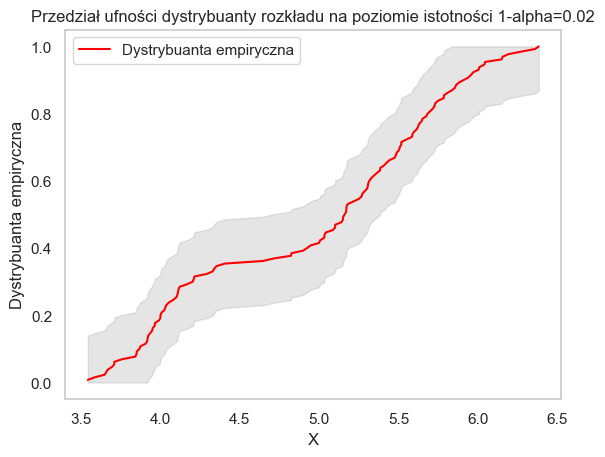

In [10]:
# Komórka testowa
test_results_3 = cdf_estimation(sample, 0.05)
assert type(test_results_3) == pd.DataFrame
assert test_results_3.shape == (130, 4)
assert list(test_results_3.columns) == ['X', 'F_d', 'F_d_min', 'F_d_max']
assert np.all(np.isclose(test_results_3.min().values, [3.54233698, 0.00769231, 0., 0.12544548]))
assert np.all(np.isclose(test_results_3.max().values, [6.38176057, 1., 0.88224683, 1.]))
assert np.all(np.isclose(test_results_3.mean().values, [4.9551826 , 0.50384615, 0.3925793 , 0.61420722]))

test_results_4 = cdf_estimation(sample, 0.02)
assert type(test_results_4) == pd.DataFrame
assert test_results_4.shape == (130, 4)
assert list(test_results_4.columns) == ['X', 'F_d', 'F_d_min', 'F_d_max']
assert np.all(np.isclose(test_results_4.min().values, [3.54233698, 0.00769231, 0., 0.13935689]))
assert np.all(np.isclose(test_results_4.max().values, [6.38176057, 1., 0.86833542, 1.]))
assert np.all(np.isclose(test_results_4.mean().values, [4.9551826 , 0.50384615, 0.380346, 0.62633351]))